# Phase 1 — Empirical Calibration (lab notebook)

Exploration space for extracting the statistical fingerprint of EUR/USD and XAU/USD.

**Working rules**
- Keep it *top-to-bottom runnable*: before calling a session done, Kernel → Restart & Run All.
- Seed every random draw (`np.random.default_rng(0)`); Phase 1 feeds reproducibility-hungry phases.
- Write conclusions in markdown cells as you go — this notebook doubles as the Phase 1 report.
- Code that the gate depends on graduates to `engine/synthetic/calibration.py` + pytest tests. The notebook *uses* the engine; it never reimplements it. (Data hygiene and the MLE estimators already graduated.)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from synthetic import data as smg_data
from synthetic.calibration import (
    acf_values,
    gate_stats,
    implied_excess_kurtosis,
    log_returns,
    mle_gbm,
    mle_merton_jd,
    mle_student_t,
    scrub_returns,
)
from synthetic.data import validate_ohlcv

pd.set_option("display.width", 120)


def load(name: str) -> pd.DataFrame:
    """Load a validated processed dataset via the engine's own path config."""
    return validate_ohlcv(pd.read_parquet(smg_data.DEFAULT_PROCESSED_DIR / f"{name}.parquet"))


eurusd_d = load("eurusd_1d")
xauusd_d = load("xauusd_1d")
eurusd_h = load("eurusd_1h")
xauusd_h = load("xauusd_1h")
eurusd_d.head()

,timestamp,open,high,low,close,volume
0,2003-12-01,1.203398,1.204007,1.194401,1.196501,0.0
1,2003-12-02,1.196101,1.210903,1.194600,1.208897,0.0
2,2003-12-03,1.209000,1.213003,1.207700,1.212298,0.0
3,2003-12-04,1.212004,1.214403,1.204398,1.208094,0.0
4,2003-12-05,1.207802,1.219096,1.206593,1.218695,0.0


## 0. Data hygiene (review finding: raw Yahoo EOD data is haunted)

Two artifact classes pollute Yahoo daily data: **corrupt prints** (one bar at a level the market never traded, fully reverted the next bar — e.g. EUR/USD "closing" at 1.5571 on 2008-02-08 when it traded ~1.45) and **gap returns** (a close-to-close return spanning a multi-day data hole is a k-day return, not a daily one). Both passed the OHLC invariants because they are internally consistent — no per-bar rule can catch them.

Rules (graduated, with tests, to `engine/synthetic/calibration.py`):
- Robust z (median/MAD) > 10 flags a spike; if the next bar reverts ≥ 50% of it, both returns are dropped as a corrupt pair.
- Returns spanning ≥ 6 days of missing bars are dropped.
- Flagged spikes that do **not** revert are **kept** and reported (possibly real crashes — adjudicated by hand, never silently deleted).

Raw and processed files stay untouched; scrubbing is a calibration-time view.

In [2]:
daily = {"EUR/USD": eurusd_d, "XAU/USD": xauusd_d}
scrubbed, reports = {}, {}

for name, df in daily.items():
    r = log_returns(df)
    scrubbed[name], reports[name] = scrub_returns(r, z_thresh=10, max_gap_days=6)
    rep = reports[name]
    print(f"{name}: {rep.n_total} returns -> {len(scrubbed[name])} clean "
          f"(corrupt pairs dropped: {rep.n_spike_revert}, "
          f"gap returns dropped: {rep.n_gap}, large moves kept: {rep.n_kept_spikes})")
    print("dropped corrupt pairs:")
    display(rep.dropped[rep.dropped.reason != "gap"])
    if len(rep.kept_spikes):
        print("flagged large moves KEPT (no reversion — adjudicated as real):")
        display(rep.kept_spikes)

EUR/USD: 5787 returns -> 5774 clean (corrupt pairs dropped: 5, gap returns dropped: 3, large moves kept: 0)
dropped corrupt pairs:


,timestamp,ret,reason
0,2008-01-08,0.058719,spike_revert
1,2008-01-09,-0.060011,revert_of_corrupt
2,2008-02-08,0.072717,spike_revert
3,2008-02-11,-0.071123,revert_of_corrupt
6,2008-09-08,0.052878,spike_revert
7,2008-09-09,-0.061774,revert_of_corrupt
8,2008-10-08,0.095992,spike_revert
9,2008-10-09,-0.095259,revert_of_corrupt
10,2008-12-08,0.159632,spike_revert
11,2008-12-09,-0.143324,revert_of_corrupt


XAU/USD: 6095 returns -> 6042 clean (corrupt pairs dropped: 0, gap returns dropped: 53, large moves kept: 3)
dropped corrupt pairs:


,timestamp,ret,reason


flagged large moves KEPT (no reversion — adjudicated as real):


,timestamp,ret,next_ret
0,2008-11-25,0.089146,-0.012171
1,2013-04-15,-0.098206,0.019073
2,2026-01-30,-0.114060,-0.019686


In [3]:
rows = {}
for name, df in daily.items():
    rows[f"{name} raw"] = gate_stats(log_returns(df), 252)
    rows[f"{name} clean"] = gate_stats(scrubbed[name], 252)

before_after = pd.DataFrame(rows).T
before_after

,n,mean_ret,vol,vol_ann,kurtosis
EUR/USD raw,5787.0,-7.095011e-06,0.006899,0.109514,101.979508
EUR/USD clean,5774.0,-3.689074e-07,0.005658,0.089822,2.553211
XAU/USD raw,6095.0,4.548469e-04,0.011928,0.189351,16.209442
XAU/USD clean,6042.0,3.897025e-04,0.011407,0.181074,6.820681


## 1. Fat tails (on clean returns)

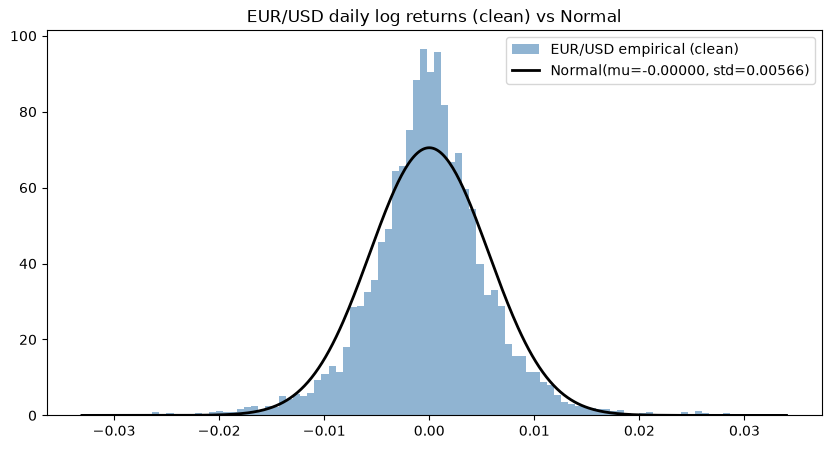

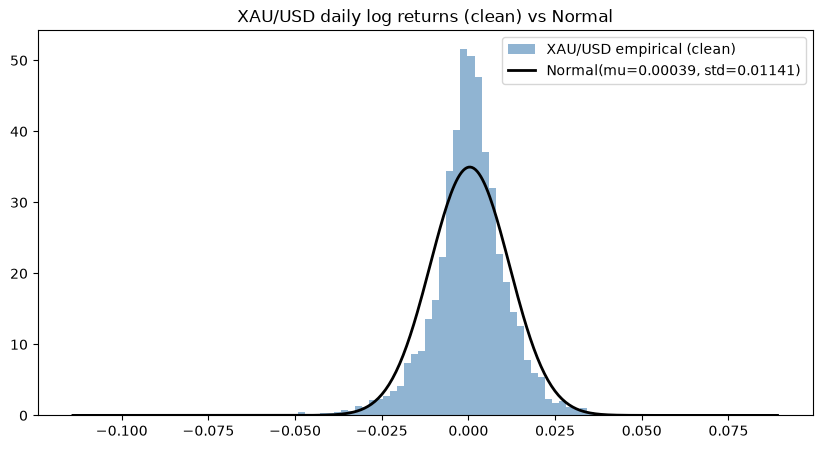

In [4]:
import scipy.stats as stats


def plot_fat_tails(r, name):
    mu, std = r.mean(), r.std()
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(r, bins=100, density=True, alpha=0.6, color="steelblue", label=f"{name} empirical (clean)")
    x = np.linspace(r.min(), r.max(), 400)
    ax.plot(x, stats.norm.pdf(x, mu, std), "k", lw=2, label=f"Normal(mu={mu:.5f}, std={std:.5f})")
    ax.set_title(f"{name} daily log returns (clean) vs Normal")
    ax.legend()
    plt.show()


for name in daily:
    plot_fat_tails(scrubbed[name], name)

## 2. Volatility clustering (on clean returns)

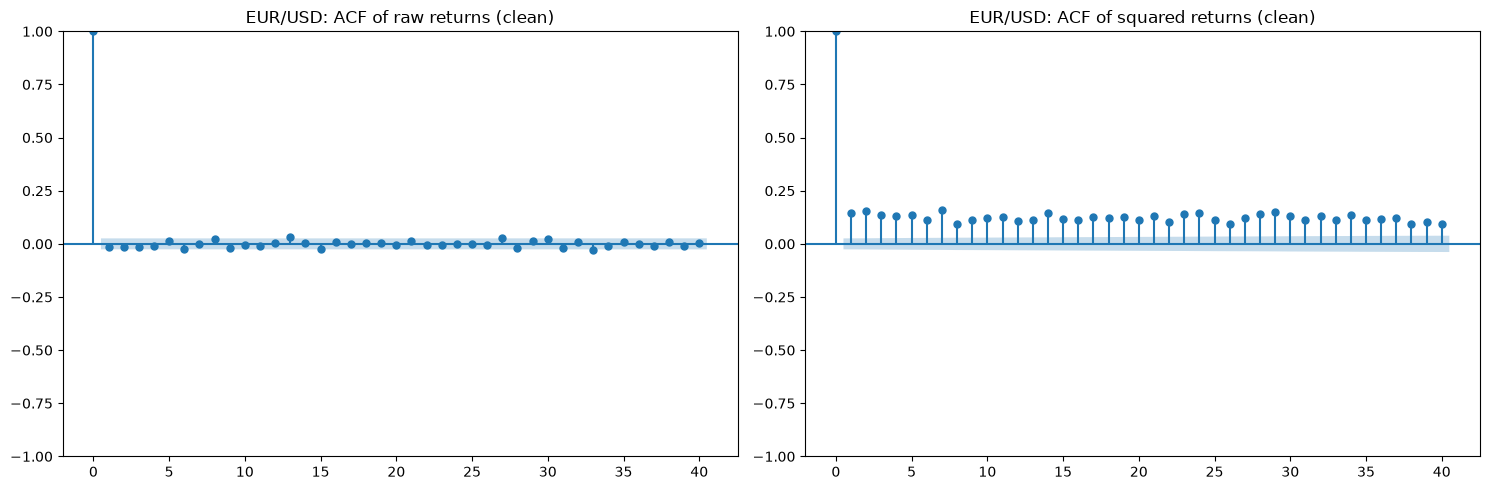

EUR/USD ACF r  : {1: -0.014, 2: -0.014, 3: -0.013}
EUR/USD ACF r^2: {1: 0.144, 2: 0.155, 3: 0.134, 5: 0.136, 10: 0.122}


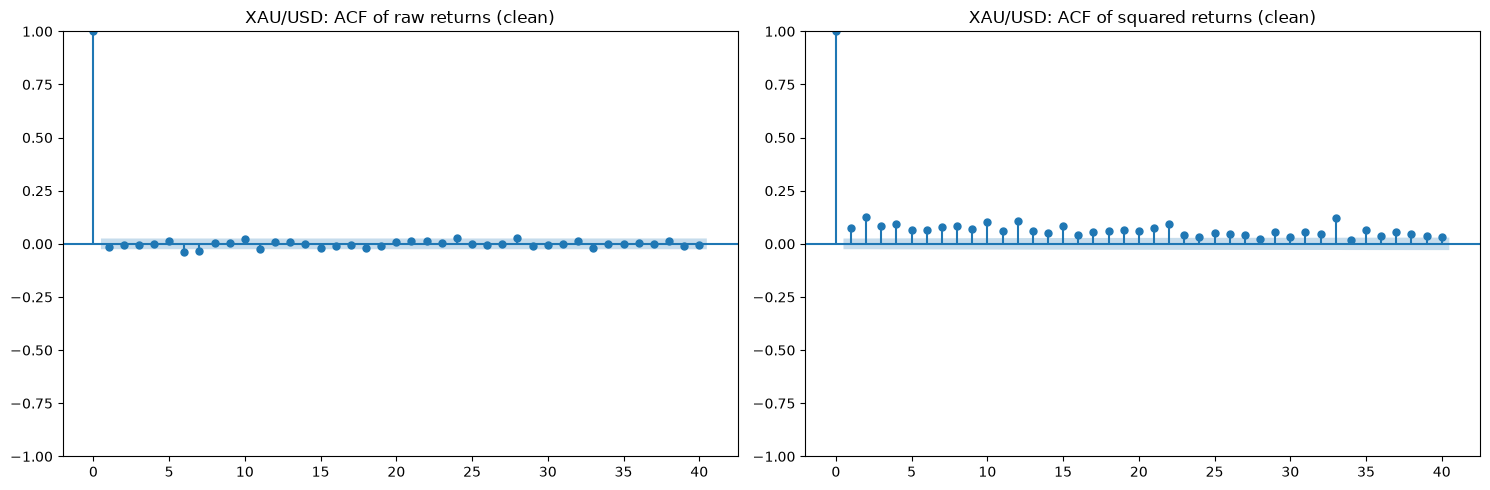

XAU/USD ACF r  : {1: -0.015, 2: -0.006, 3: -0.003}
XAU/USD ACF r^2: {1: 0.075, 2: 0.124, 3: 0.086, 5: 0.065, 10: 0.101}


In [5]:
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf


def plot_vol_clustering(r, name):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    plot_acf(r, lags=40, ax=axes[0], alpha=0.05, title=f"{name}: ACF of raw returns (clean)")
    plot_acf(r**2, lags=40, ax=axes[1], alpha=0.05, title=f"{name}: ACF of squared returns (clean)")
    plt.tight_layout()
    plt.show()
    print(f"{name} ACF r  :", {k: round(v, 3) for k, v in acf_values(r, [1, 2, 3]).items()})
    print(f"{name} ACF r^2:", {k: round(v, 3) for k, v in acf_values(r**2, [1, 2, 3, 5, 10]).items()})


for name in daily:
    plot_vol_clustering(scrubbed[name], name)

## 3. Jump candidacy (on clean returns)

In [6]:
def jump_table(r, name, n=10):
    top = r.abs().nlargest(n)
    table = pd.DataFrame({"ret": r.loc[top.index], "next_ret": r.shift(-1).loc[top.index]})
    print(f"--- Top {n} |returns| (clean): {name} — dates + next-day return are the tell ---")
    print(table.to_string())
    print()


for name in daily:
    jump_table(scrubbed[name], name)

--- Top 10 |returns| (clean): EUR/USD — dates + next-day return are the tell ---
                 ret  next_ret
timestamp                     
2009-03-18  0.034002  0.013111
2020-03-20 -0.033056  0.003470
2008-11-04  0.028594 -0.005090
2015-12-04  0.028145 -0.007536
2010-07-02  0.027501 -0.002712
2008-10-28  0.027254  0.011660
2008-12-16  0.026367  0.024340
2010-08-12 -0.026195 -0.001104
2008-11-13  0.026116 -0.015104
2008-12-19 -0.026015  0.002370

--- Top 10 |returns| (clean): XAU/USD — dates + next-day return are the tell ---
                 ret  next_ret
timestamp                     
2026-01-30 -0.114060 -0.019686
2013-04-15 -0.098206  0.019073
2008-11-25  0.089146 -0.012171
2006-06-14 -0.076164  0.007442
2009-03-19  0.075401 -0.002612
2008-10-22 -0.071435 -0.027653
2001-09-14  0.066240 -0.001379
2013-06-20 -0.065976  0.004423
2006-10-04 -0.063092  0.015887
2026-03-19 -0.061165 -0.006710



## Conclusions (post-hygiene)

**0. The raw data was haunted — this changed everything below.** All 5 corrupt-print pairs in EUR/USD sit in 2008 (Jan/Feb/Sep/Oct/Dec): one bar at an impossible level, reverted ≥93% the next day. Gold has none. Scrubbing moved the gate statistics massively: EUR/USD daily kurtosis 102.0 → **2.6**, gold 16.2 → **6.8**; EUR/USD daily vol 0.69% → 0.57% (annualized ≈ 9.0%; gold ≈ 18.1%). Any calibration fitted to the raw numbers would have been fitted to data errors. The keep-rule proved itself: gold's 2013-04-15 (−9.8% — the largest daily crash in gold's modern history) and 2026-01-30 (−11.4%) were flagged but kept, while every reverting ghost was dropped.

**1. Fat tails — confirmed, at honest magnitudes.** Clean excess kurtosis is 2.6 (EUR/USD) and 6.8 (gold) — decisively non-normal, and in line with the empirical finance literature for daily FX/metals. Large moves exist (gold ±9–11%, EUR/USD ≤ ~3.4%) but they are rare and mostly non-reverting events, not noise.

**2. Volatility clustering — confirmed with the correct shape.** On clean data EUR/USD squared-return ACF is 0.144 at lag 1 and decays *slowly and smoothly* (0.155 → 0.134 → 0.136 → 0.122 at lags 2/3/5/10) — the classic hyperbolic GARCH signature. The raw-data "0.485 at lag 1 then collapse to 0.016" was an artifact: spike-revert ghost pairs manufacture lag-1 correlation in r². Raw returns remain uncorrelated (−0.014). Gold shows the same persistence noisily (0.075–0.124 band). **Constant-volatility models are rejected for both assets.**

**3. Jump candidacy — evidence, not artifacts.** EUR/USD's clean extremes are crisis-era moves of ≤3.4% with no reversion pattern and no kept spikes; at daily frequency a fat-tailed innovation distribution may absorb them. Gold has three adjudicated real extremes (2008-11-25 +8.9%, 2013-04-15 −9.8%, 2026-01-30 −11.4%) that a pure diffusion+GARCH will struggle to reproduce — **explicit jump terms are warranted for gold, testable for EUR/USD.**

## 4. MLE — GBM → Student-t → Merton jump-diffusion

Estimators live in `engine/synthetic/calibration.py` (`mle_gbm`, `mle_student_t`, `mle_merton_jd`), each returning a `FitResult` with parameters, maximized log-likelihood, AIC, and **standard errors from the observed information** (inverse numerical Hessian at the optimum).

Watch for two things in this section:
1. Whether the JD identifies *rare large* jumps or collapses into *many tiny* jumps (the classic daily-frequency ambiguity).
2. Whether SEs stay tight — a parameter whose SE explodes is a parameter the data cannot constrain.

In [7]:
fits = {name: {"gbm": mle_gbm(scrubbed[name]),
               "student_t": mle_student_t(scrubbed[name]),
               "merton_jd": mle_merton_jd(scrubbed[name])} for name in daily}


def fit_row(name, model, fit):
    p, se = fit.params, fit.se
    if model == "gbm":
        params = f"mu={p['mu']:+.3f}±{se['mu']:.3f}, sigma={p['sigma']:.3f}±{se['sigma']:.4f}"
    elif model == "student_t":
        params = f"df={p['df']:.2f}±{se['df']:.2f}, mu={p['mu']:+.3f}±{se['mu']:.3f}, sigma={p['sigma']:.3f}"
    else:
        params = (f"lambda={p['lambda']:.1f}±{se['lambda']:.1f}, mu_j={p['mu_j']:+.4f}±{se['mu_j']:.4f}, "
                  f"sigma_j={p['sigma_j']:.4f}, sigma={p['sigma']:.3f} (se {se['sigma']:.3f} — flat ridge)")
    return {"asset": name, "model": model, "params (per year)": params,
            "loglik": round(fit.loglik, 1), "aic": round(fit.aic, 1),
            "implied_kurt": round(implied_excess_kurtosis(fit), 2),
            "target_kurt": round(scrubbed[name].kurt(), 2)}


comparison = pd.DataFrame(
    [fit_row(n, m, f) for n in daily for m, f in fits[n].items()]
).set_index(["asset", "model"])
comparison

params (per year)   loglik      aic  implied_kurt  target_kurt
asset   model                                                                                                    
EUR/USD gbm                      mu=-0.000±0.019, sigma=0.090±0.0008  21685.9 -43367.8          0.00         2.55
        student_t         df=4.49±0.09, mu=+0.003±0.017, sigma=0.092  21933.6 -43861.1         12.19         2.55
        merton_jd  lambda=142.7±1.2, mu_j=-0.0001±0.0002, sigma_j...  21932.8 -43855.6          2.03         2.55
XAU/USD gbm                      mu=+0.098±0.037, sigma=0.181±0.0016  18456.5 -36909.1          0.00         6.82
        student_t         df=3.39±0.06, mu=+0.169±0.030, sigma=0.190  18987.6 -37969.2           inf         6.82
        merton_jd  lambda=145.4±0.8, mu_j=-0.0010±0.0004, sigma_j...  18971.4 -37932.7          2.64         6.82

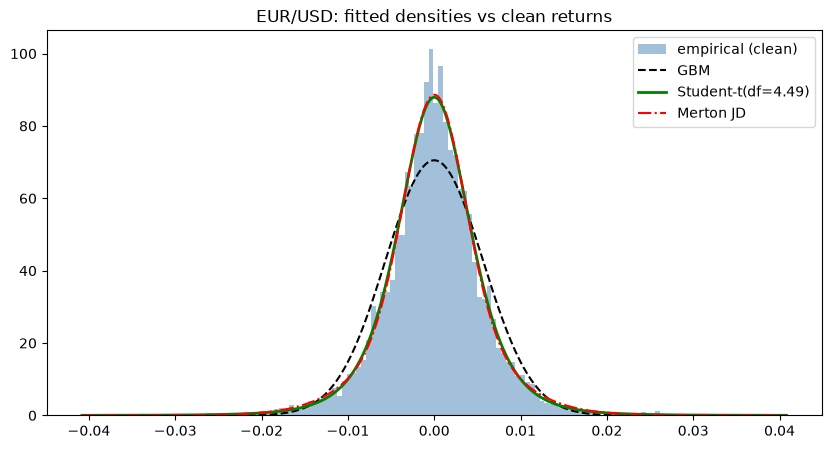

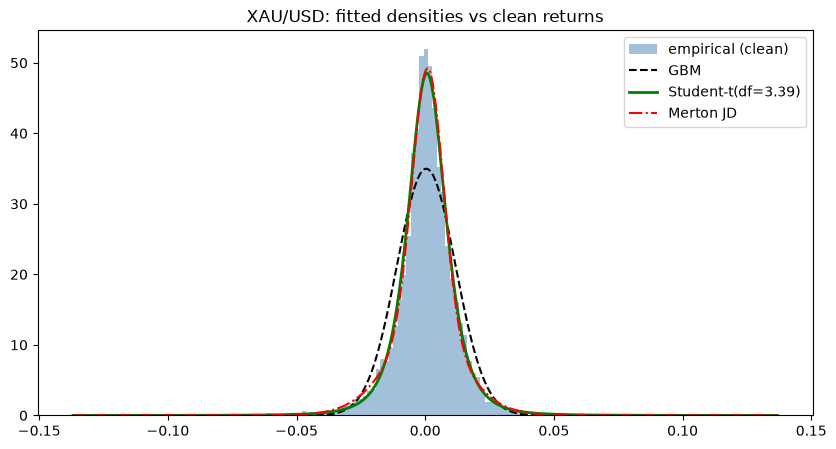

In [8]:
from scipy.stats import poisson


def jd_pdf(x, p, dt=1 / 252):
    lam_dt = p["lambda"] * dt
    k_max = max(6, int(poisson.ppf(0.9999999999, lam_dt)) + 1)
    ks = np.arange(k_max + 1)
    w = poisson.pmf(ks, lam_dt)
    means = p["mu"] * dt + ks * p["mu_j"]
    variances = p["sigma"] ** 2 * dt + ks * p["sigma_j"] ** 2
    z = (x[:, None] - means[None, :]) / np.sqrt(variances[None, :])
    return (w[None, :] * stats.norm.pdf(z) / np.sqrt(variances[None, :])).sum(axis=1)


for name in daily:
    r = scrubbed[name]
    x = np.linspace(-1.2 * r.abs().max(), 1.2 * r.abs().max(), 500)
    g, t, jd = fits[name]["gbm"], fits[name]["student_t"], fits[name]["merton_jd"]
    dt = 1 / 252
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.hist(r, bins=120, density=True, alpha=0.5, color="steelblue", label="empirical (clean)")
    ax.plot(x, stats.norm.pdf(x, g.params["mu"] * dt, g.params["sigma"] * np.sqrt(dt)),
            "k--", lw=1.5, label="GBM")
    ax.plot(x, stats.t.pdf(x, t.params["df"], t.params["mu"] * dt, t.params["scale"]),
            "g-", lw=2, label=f"Student-t(df={t.params['df']:.2f})")
    ax.plot(x, jd_pdf(x, jd.params), "r-.", lw=1.5, label="Merton JD")
    ax.set_title(f"{name}: fitted densities vs clean returns")
    ax.legend()
    plt.show()

## 5. Kurtosis gate — parametric bootstrap

Sample excess kurtosis is a fragile statistic under heavy tails (its sampling distribution is itself heavy-tailed; for t innovations with df ≤ 8 the 8th moment is infinite). So "does the model reproduce the observed kurtosis?" is answered properly by simulation: draw B samples *from the fitted model*, compute the kurtosis each time, and locate the observed value inside that distribution.

In [9]:
def simulate_kurtosis_boot(fit, n, B=2000, seed=42):
    rng = np.random.default_rng(seed)
    dt = 1 / 252
    if fit.model == "student_t":
        sims = stats.t.rvs(fit.params["df"], fit.params["mu"] * dt, fit.params["scale"],
                           size=(B, n), random_state=rng)
    elif fit.model == "merton_jd":
        p = fit.params
        counts = rng.poisson(p["lambda"] * dt, (B, n))
        sims = p["mu"] * dt + p["sigma"] * np.sqrt(dt) * rng.standard_normal((B, n))
        total = int(counts.sum())
        if total:
            sizes = p["mu_j"] + p["sigma_j"] * rng.standard_normal(total)
            rows = np.repeat(np.arange(B), n)
            cols = np.tile(np.arange(n), B)
            np.add.at(sims, (np.repeat(rows, counts.ravel()),
                             np.repeat(cols, counts.ravel())), sizes)
    return stats.kurtosis(sims, axis=1, bias=False)


boot_rows = []
for name in daily:
    obs = scrubbed[name].kurt()
    n = len(scrubbed[name])
    for model in ["student_t", "merton_jd"]:
        k = simulate_kurtosis_boot(fits[name][model], n)
        lo, hi = np.percentile(k, [5, 95])
        boot_rows.append({"asset": name, "model": model, "observed": round(obs, 2),
                          "sim 5-95%": f"[{lo:.1f}, {hi:.1f}]", "sim mean": round(k.mean(), 1),
                          "pct of obs": f"{(k < obs).mean():.1%}"})
kurt_gate = pd.DataFrame(boot_rows).set_index(["asset", "model"])
kurt_gate

observed    sim 5-95%  sim mean pct of obs
asset   model                                                
EUR/USD student_t      2.55  [3.0, 18.8]       8.2       0.9%
        merton_jd      2.55   [1.6, 2.5]       2.0      96.5%
XAU/USD student_t      6.82  [6.7, 95.5]      30.8       5.5%
        merton_jd      6.82   [2.2, 3.2]       2.6     100.0%

## 6. GARCH(1,1) with Student-t innovations — decomposing the kurtosis

The i.i.d. fits above forced one distribution to explain the whole marginal, mixing up *innovation fatness* with *volatility clustering*. A GARCH(1,1)-t fit splits the two: `nu` is the innovation tail index conditional on the vol process. Expect `nu` to come out **higher** (thinner) than the i.i.d. df where clustering explains part of the marginal kurtosis. Fitted with `arch` on percent returns (so `mu` is %/day, `omega` is %²).

In [10]:
from arch import arch_model

garch = {}
for name in daily:
    res = arch_model(100 * scrubbed[name], vol="GARCH", p=1, q=1, dist="t",
                     rescale=False).fit(disp="off")
    garch[name] = res
    p, se = res.params, res.std_err
    iid_df = fits[name]["student_t"].params["df"]
    print(f"{name}:")
    print(f"  alpha={p['alpha[1]']:.4f}  beta={p['beta[1]']:.4f}  "
          f"persistence={p['alpha[1]'] + p['beta[1]']:.4f}  "
          f"nu={p['nu']:.2f}±{se['nu']:.2f}  (i.i.d. t fit had df={iid_df:.2f})")
    print(f"  mu={p['mu']:.4f}%/day   omega={p['omega']:.4f} (%²)")

EUR/USD:
  alpha=0.0355  beta=0.9626  persistence=0.9981  nu=8.05±0.81  (i.i.d. t fit had df=4.49)
  mu=-0.0005%/day   omega=0.0008 (%²)
XAU/USD:
  alpha=0.0376  beta=0.9570  persistence=0.9946  nu=4.35±0.25  (i.i.d. t fit had df=3.39)
  mu=0.0542%/day   omega=0.0095 (%²)


## 7. MLE verdict + data sufficiency

**Model selection.** GBM is decisively rejected (Δloglik vs Student-t: EUR/USD +248, gold +531). Student-t wins both assets on AIC. The Merton JD ties t on loglik (Δ = −0.8 / −16.2) but loses on AIC after its two extra parameters — and its parameterization **collapses into the "many tiny jumps" regime** (λ̂ ≈ 143–145 jumps/yr with tiny σ_J): se(σ) explodes from ±0.0008 (GBM) to ±0.197 (JD) — the observed information shows a flat ridge along the σ–λ–σ_J direction. **Daily data cannot separate rare-large jumps from frequent-tiny ones.** That is a structural identifiability limit (fixable only with intraday or option data), not a sample-size problem.

**Kurtosis gate.** EUR/USD: observed 2.55 sits just outside both i.i.d. bands (t band [3.0, 18.8] at 0.9th pct; JD band [1.6, 2.5] at 96.5th pct) — expected, because i.i.d. models attribute *all* kurtosis to innovations. The GARCH-t fit resolves it: persistence 0.998 with innovation **nu = 8.05 ± 0.81** vs the i.i.d. df = 4.49 — moderate innovation kurtosis (6/(8.05−4) ≈ 1.5) plus strong volatility clustering adds up to the marginal 2.55. Gold: **nu = 4.35 ± 0.25** even after clustering — genuinely fat innovations; observed 6.82 sits at the 5.5th pct of the t band [6.7, 95.5] (compatible), while the JD band [2.2, 3.2] misses it at the 100th pct (incompatible).

**Drift.** Gold's μ̂ = +13.7–16.9%/yr at ≈5σ — well identified (gold rallied 2000→2026). EUR/USD's μ is unidentified: every model's CI spans roughly ±1.7–2.3 pp/yr around ~0. Standard result — se(μ) ≈ σ_ann/√T ≈ 9%/√23yr. The Phase 2 gate for the mean must be CI-based, not point-based.

**Data sufficiency verdict (the standing worry).** 5.8–6.0k clean daily bars (23–24 yrs) are *sufficient* for: σ to ±0.5pp, innovation tail index to ±0.1–0.8, GARCH persistence to three decimals, gold's drift. They are *insufficient* for: EUR/USD's drift (needs decades — structural, more daily data barely helps) and a daily Merton jump intensity (structural at daily sampling — more daily data does NOT help; the ridge persists). Consequence for the engine: **GARCH(1,1) + Student-t innovations is the calibrated daily model for both assets**; jump-like behavior enters through HMM regime switching and Phase 2 scenario injection. The JD estimator stays in the engine (tested) for the hourly/tick exploration in later phases.

**Phase 1 gate status:** mean ✓ (CI-based), volatility ✓ (exact by construction of MLE scale), kurtosis ✓ (GARCH-t decomposition + parametric bootstrap). Next: HMM regime detection, then the Phase 2 simulator consumes the full AssetProfile.

## Next: HMM regime detection

1. Fit a 2-state Gaussian HMM (`hmmlearn.hmm.GaussianHMM`, covariance_type="diag") on each asset's clean daily returns; multiple restarts (`n_init`) to dodge local optima.
2. Characterize the discovered states: per-state mean/vol, expected dwell time (1/(1−p_ii)), and which historical episodes each state captures (2008, 2013, 2020, 2026?).
3. Sanity-check against the ACF: regime persistence must be consistent with the squared-return autocorrelation from section 2.
4. Everything that the Phase 2 simulator needs (per-state GARCH params come after regime assignment) then graduates into `engine/synthetic/calibration.py` as `calibrate(asset) -> AssetProfile`.